# Model 3: Feed-forward network: CNN denoiser + GAN enhancement

Run the cells from top to bottom. **Part 1** trains the CNN and saves the best one. **Part 2** uses that CNN as the GAN generator. The final cell compares input, CNN and CNN + GAN on the 15 test images.

On Kaggle: attach the LOL dataset, turn on a GPU, and use *Save Version > Save & Run All* to run it unattended; the models and result files are then kept in the notebook's output.

If you hit an out-of-memory error: restart the session, run the cells from the top again, and carry on. Settings that already finished are skipped (their results are saved as small .json files).

In [1]:
# # Mount Google Drive when running in Colab (skipped automatically anywhere else)
# try:
#     from google.colab import drive
#     drive.mount('/content/drive')
# except ImportError:
#     print('Not running in Colab - using the paths from the CONFIG cell')

In [2]:
import os
# Lets TensorFlow hand GPU memory back between runs. Must be set before TensorFlow is imported.
# Delete this line if TensorFlow complains about it.
os.environ['TF_GPU_ALLOCATOR'] = 'cuda_malloc_async'

import gc, json, shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import (Input, Conv2D, Conv2DTranspose, UpSampling2D, MaxPooling2D,
                                     BatchNormalization, Activation, ReLU, LeakyReLU, Concatenate,
                                     Flatten, Dense, Reshape, GlobalAveragePooling2D)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.model_selection import train_test_split, ParameterGrid

In [3]:
# ============================== CONFIG (edit here only) ==============================
MODEL_NAME = 'model3_feedforward'
IMG_SIZE   = (200, 300)    # (height, width). Smaller = less GPU memory. Both stages use this size.
SEED       = 42
PATIENCE   = 10            # CNN early stopping patience in epochs (None = always train all epochs)
EVAL_EVERY = 10            # GAN: check validation PSNR every N epochs
KEEP_ONLY_BEST = True      # delete non-best model files after each sweep to save disk space

if os.path.exists('/kaggle/input'):                       # running on Kaggle
    SAVE_DIR  = '/kaggle/working/lowlight_models/'
    DATA_PATH = None
    for root, dirs, files in os.walk('/kaggle/input'):    # find the folder that contains our485/
        if 'our485' in dirs:
            DATA_PATH = root + '/'
            break
    assert DATA_PATH, 'Could not find our485/ - attach the LOL dataset to this notebook'
else:                                                     # Colab
    DATA_PATH = '/content/drive/MyDrive/LOL_dataset/lol_dataset/'
    SAVE_DIR  = '/content/drive/MyDrive/lowlight_models/'
print('Dataset:', DATA_PATH)

CNN_BEST_PATH = os.path.join(SAVE_DIR, MODEL_NAME + '_cnn_best.keras')   # written by Part 1, read by Part 2
GAN_BEST_PATH = os.path.join(SAVE_DIR, MODEL_NAME + '_gan_best.keras')
# =====================================================================================

os.makedirs(SAVE_DIR, exist_ok=True)
input_shape = (*IMG_SIZE, 3)
tf.keras.utils.set_random_seed(SEED)

for gpu in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print('Skipping memory growth setting:', e)
print('GPUs available:', len(tf.config.list_physical_devices('GPU')))

Dataset: /kaggle/input/datasets/lindaraju/loldataset/LOL_dataset/lol_dataset/
GPUs available: 2


## Load data

In [4]:
def load_images(folder):
    folder_path = os.path.join(DATA_PATH, folder)
    images = []
    for filename in sorted(os.listdir(folder_path)):      # sorted, so low/high images stay paired
        img = load_img(os.path.join(folder_path, filename), target_size=IMG_SIZE)
        images.append(img_to_array(img) / 255.0)          # scale pixels to [0, 1]
    return np.array(images, dtype='float32')

low_all  = load_images('our485/low')
high_all = load_images('our485/high')

# One call splits both arrays with the same shuffle (same 80/20 split as the original notebook)
(train_low_light_images, val_low_light_images,
 train_normal_light_images, val_normal_light_images) = train_test_split(
    low_all, high_all, test_size=0.2, random_state=SEED)
del low_all, high_all

test_low_light_images    = load_images('eval15/low')
test_normal_light_images = load_images('eval15/high')

print('train:', train_low_light_images.shape, '| val:', val_low_light_images.shape,
      '| test:', test_low_light_images.shape)

train: (388, 200, 300, 3) | val: (97, 200, 300, 3) | test: (15, 200, 300, 3)


In [5]:
def score(reference, prediction, batch=8):
    """MSE / PSNR / SSIM averaged over ALL images (pixel range 0-1), compared with the normal-light target."""
    mses, psnrs, ssims = [], [], []
    for i in range(0, len(reference), batch):
        ref = reference[i:i + batch]
        pred = np.clip(prediction[i:i + batch], 0.0, 1.0)
        mses.append(np.mean((ref - pred) ** 2, axis=(1, 2, 3)))
        psnrs.append(tf.image.psnr(ref, pred, max_val=1.0).numpy())
        ssims.append(tf.image.ssim(ref, pred, max_val=1.0).numpy())
    return {'mse':  float(np.concatenate(mses).mean()),
            'psnr': float(np.concatenate(psnrs).mean()),
            'ssim': float(np.concatenate(ssims).mean())}

def show_results(columns, titles, n=3):
    """Plot n rows of images; each entry of `columns` is an array of images, one column per entry."""
    fig, axes = plt.subplots(n, len(columns), figsize=(4 * len(columns), 2.8 * n), squeeze=False)
    for i in range(n):
        for j, (imgs, title) in enumerate(zip(columns, titles)):
            axes[i, j].imshow(np.clip(imgs[i], 0, 1))
            axes[i, j].axis('off')
            if i == 0:
                axes[i, j].set_title(title)
    plt.tight_layout()
    plt.show()

# Part 1: CNN denoiser

## Model

In [6]:
# Model 3: feed-forward (fully connected) network on the flattened image.
# WARNING: at 400x600 this has about 1.1 billion parameters (needs a large GPU, ~13 GB with Adam).
# Lower IMG_SIZE in the CONFIG cell (e.g. (200, 300)) to make it smaller.
def build_model():
    model = Sequential(name=MODEL_NAME)
    model.add(Input(shape=input_shape))
    model.add(Flatten())

    # Fully connected layers
    model.add(Dense(1024, activation='relu'))
    model.add(Dense(512, activation='relu'))

    # Output layer (values in [0, 1]), reshaped back to an image
    model.add(Dense(int(np.prod(input_shape)), activation='sigmoid'))
    model.add(Reshape(input_shape))
    return model

build_model().summary()

I0000 00:00:1792060027.312106     123 gpu_process_state.cc:208] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1792060027.314729     123 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792060027.316093     123 gpu_process_state.cc:208] Using CUDA malloc Async allocator for GPU: 1
I0000 00:00:1792060027.317820     123 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "model3_feedforward"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 180000)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │   184,321,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 180000)         │    92,340,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 200, 300, 3)    │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 277,185,824 (1.03 GB)

 Trainable params: 277,185,824 (1.03 GB)

 Non-trainable params: 0 (0.00 B)

## Train (hyperparameter sweep)

In [7]:
def train_one(params):
    """Train one hyperparameter setting. Returns its validation scores and the checkpoint path."""
    tag = f"{IMG_SIZE[0]}x{IMG_SIZE[1]}_lr{params['learning_rate']}_bs{params['batch_size']}_ep{params['epochs']}"
    ckpt = os.path.join(SAVE_DIR, f'{MODEL_NAME}_cnn_{tag}.keras')     # one file per setting
    done_path = ckpt.replace('.keras', '.json')
    if os.path.exists(done_path):                  # finished earlier (e.g. before a restart): reuse its result
        print('Skipping (already finished):', tag)
        with open(done_path) as f:
            return json.load(f)

    K.clear_session()
    model = build_model()
    # jit_compile=False: skips XLA, a common source of 'InternalError: Graph execution error' on Colab GPUs
    model.compile(optimizer=Adam(learning_rate=params['learning_rate']), loss='mse', jit_compile=False)

    callbacks = [ModelCheckpoint(ckpt, monitor='val_loss', save_best_only=True)]
    if PATIENCE:
        callbacks.append(EarlyStopping(monitor='val_loss', patience=PATIENCE))

    model.fit(train_low_light_images, train_normal_light_images,
              epochs=params['epochs'], batch_size=params['batch_size'],
              validation_data=(val_low_light_images, val_normal_light_images),
              callbacks=callbacks)

    best_epoch_model = load_model(ckpt, compile=False)                  # best epoch, not the last one
    val_pred = best_epoch_model.predict(val_low_light_images, batch_size=8, verbose=0)
    result = {'params': params, 'ckpt': ckpt, **score(val_normal_light_images, val_pred)}
    with open(done_path, 'w') as f:
        json.dump(result, f, indent=2)

    del model, best_epoch_model, val_pred          # free memory only after the result is built
    K.clear_session()
    gc.collect()
    return result

In [ ]:
param_grid = {'learning_rate': [0.01, 0.001, 0.0001], 'epochs': [50], 'batch_size': [8]}

In [9]:
results = []
for params in ParameterGrid(param_grid):
    r = train_one(params)
    results.append(r)
    print(f"{r['params']} -> val MSE {r['mse']:.5f} | PSNR {r['psnr']:.2f} dB | SSIM {r['ssim']:.4f}")
    gc.collect()

# Keep the best setting (highest validation PSNR) under one fixed name, for the GAN notebook
best_run = max(results, key=lambda r: r['psnr'])
shutil.copy(best_run['ckpt'], CNN_BEST_PATH)
with open(os.path.join(SAVE_DIR, f'{MODEL_NAME}_cnn_results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print('\nBest setting:', best_run['params'], '\nSaved to:', CNN_BEST_PATH)

Epoch 1/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 22s 388ms/step - loss: 0.0486 - val_loss: 0.0495
Epoch 2/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 19s 393ms/step - loss: 0.0427 - val_loss: 0.0451
Epoch 3/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 19s 394ms/step - loss: 0.0392 - val_loss: 0.0426
Epoch 4/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 19s 390ms/step - loss: 0.0363 - val_loss: 0.0399
Epoch 5/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 161ms/step - loss: 0.0338 - val_loss: 0.0410
Epoch 6/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 161ms/step - loss: 0.0311 - val_loss: 0.0411
Epoch 7/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 160ms/step - loss: 0.0305 - val_loss: 0.0428
Epoch 8/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 160ms/step - loss: 0.0303 - val_loss: 0.0405
Epoch 9/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 19s 383ms/step - loss: 0.0289 - val_loss: 0.0380
Epoch 10/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 19s 399ms/step - loss: 0.0267 - val_loss: 0.0374
Epoch 11/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 19s 391ms/step - loss: 0.0265 - val_loss: 0.0355
Epoch 12/50
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 160

I0000 00:00:1792060512.199477     186 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


{'batch_size': 8, 'epochs': 50, 'learning_rate': 0.001} -> val MSE 0.02955 | PSNR 16.49 dB | SSIM 0.4869

Best setting: {'batch_size': 8, 'epochs': 50, 'learning_rate': 0.001} 
Saved to: /kaggle/working/lowlight_models/model3_feedforward_cnn_best.keras


In [10]:
# Free disk space: keep only the best setting's model file (the small .json result files stay)
if KEEP_ONLY_BEST:
    for r in results:
        if r['ckpt'] != best_run['ckpt'] and os.path.exists(r['ckpt']):
            os.remove(r['ckpt'])

## CNN test

Input (no model): {'mse': 0.19401948153972626, 'psnr': 7.772937297821045, 'ssim': 0.1795925498008728}
CNN             : {'mse': 0.026726845651865005, 'psnr': 16.53699493408203, 'ssim': 0.5155371427536011}


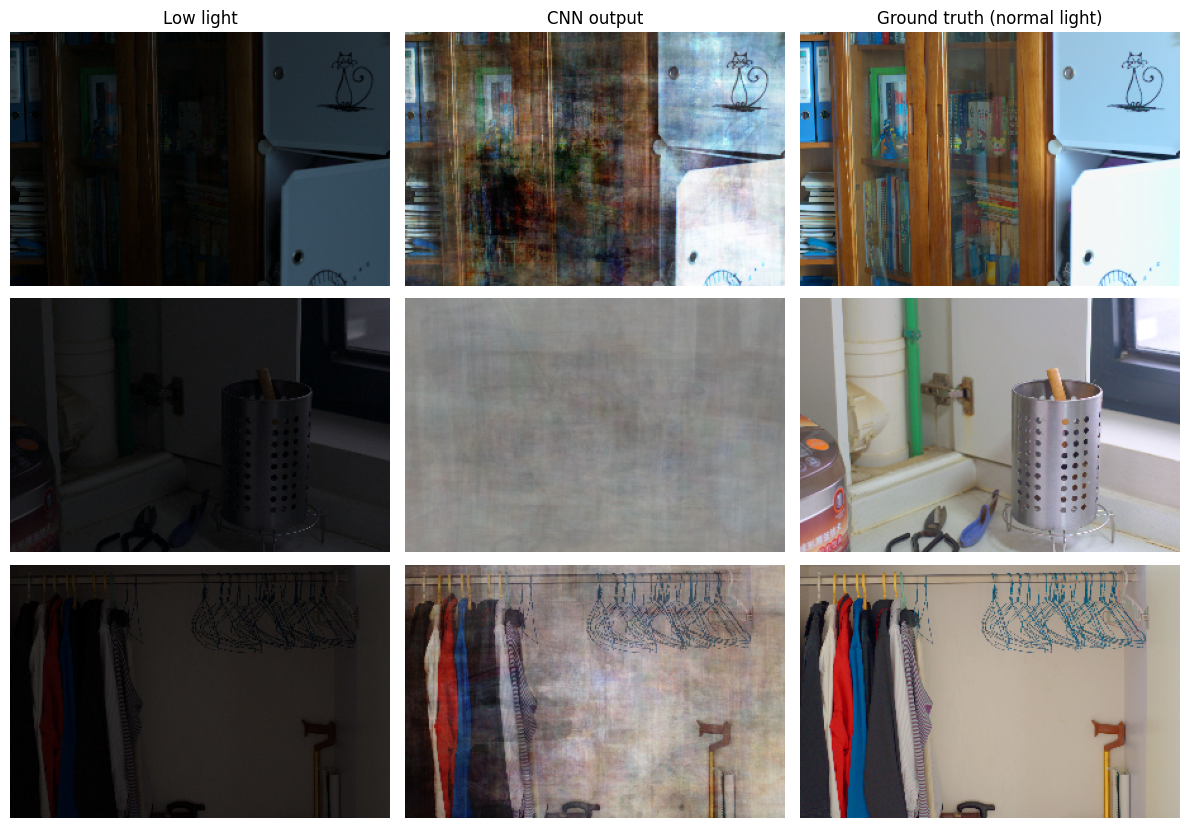

In [11]:
# Final check on the 15 held-out test images
best_model = load_model(CNN_BEST_PATH, compile=False)
test_pred = best_model.predict(test_low_light_images, batch_size=8, verbose=0)

test_scores = {'input': score(test_normal_light_images, test_low_light_images),
               'cnn':   score(test_normal_light_images, test_pred)}
print('Input (no model):', test_scores['input'])
print('CNN             :', test_scores['cnn'])

# Saved so a final summary can compare all models side by side
with open(os.path.join(SAVE_DIR, f'{MODEL_NAME}_cnn_test.json'), 'w') as f:
    json.dump(test_scores, f, indent=2)

show_results([test_low_light_images, test_pred, test_normal_light_images],
             ['Low light', 'CNN output', 'Ground truth (normal light)'])

# Part 2: GAN stage (the CNN above becomes the generator)

## Discriminator and CNN reference score

In [12]:
def build_discriminator():
    """Outputs a grid of real/fake logits (PatchGAN style) instead of one giant Dense layer."""
    inputs = Input(shape=input_shape)
    x = Conv2D(64, 4, strides=2, padding='same')(inputs)
    x = LeakyReLU(0.2)(x)
    x = Conv2D(128, 4, strides=2, padding='same')(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(0.2)(x)
    x = Conv2D(256, 4, strides=2, padding='same')(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(0.2)(x)
    outputs = Conv2D(1, 3, padding='same')(x)          # logits, no sigmoid
    return Model(inputs, outputs, name='discriminator')

# Reference point: the pre-trained CNN on its own, scored on the validation set
cnn_model = load_model(CNN_BEST_PATH, compile=False)
cnn_val = score(val_normal_light_images, cnn_model.predict(val_low_light_images, batch_size=8, verbose=0))
print('CNN only (validation):', cnn_val)
del cnn_model

CNN only (validation): {'mse': 0.02954641543328762, 'psnr': 16.494203567504883, 'ssim': 0.48690447211265564}


## Train the GAN (hyperparameter sweep)

In [13]:
def train_gan_run(params):
    """Fine-tune the pre-trained CNN as the GAN generator for one hyperparameter setting."""
    tag = f"{IMG_SIZE[0]}x{IMG_SIZE[1]}_lr{params['learning_rate']}_bs{params['batch_size']}_ep{params['epochs']}"
    path = os.path.join(SAVE_DIR, f'{MODEL_NAME}_gan_{tag}.keras')
    done_path = path.replace('.keras', '.json')
    if os.path.exists(done_path):                  # finished earlier (e.g. before a restart): reuse its result
        print('Skipping (already finished):', tag)
        with open(done_path) as f:
            return json.load(f)

    K.clear_session()
    generator = load_model(CNN_BEST_PATH, compile=False)   # pre-trained CNN = generator (weights stay trainable)
    discriminator = build_discriminator()

    g_opt = Adam(params['learning_rate'], beta_1=0.5)
    d_opt = Adam(params['learning_rate'], beta_1=0.5)
    g_opt.build(generator.trainable_variables)
    d_opt.build(discriminator.trainable_variables)
    bce = keras.losses.BinaryCrossentropy(from_logits=True)
    adv_weight = params['adv_weight']

    @tf.function
    def train_step(low, high):
        with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
            fake = generator(low, training=True)
            real_logits = discriminator(high, training=True)
            fake_logits = discriminator(fake, training=True)

            # Discriminator: real -> 1, generated -> 0
            d_loss = 0.5 * (bce(tf.ones_like(real_logits), real_logits) +
                            bce(tf.zeros_like(fake_logits), fake_logits))
            # Generator: stay close to the target (MSE) + fool the discriminator (adversarial)
            content_loss = tf.reduce_mean(tf.square(high - fake))
            adv_loss = bce(tf.ones_like(fake_logits), fake_logits)
            g_loss = content_loss + adv_weight * adv_loss

        g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
        d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
        g_opt.apply_gradients(zip(g_grads, generator.trainable_variables))
        d_opt.apply_gradients(zip(d_grads, discriminator.trainable_variables))
        return d_loss, g_loss, content_loss

    n, bs = len(train_low_light_images), params['batch_size']
    best_psnr, best_weights = -np.inf, None
    for epoch in range(1, params['epochs'] + 1):
        d_hist, g_hist, c_hist = [], [], []
        for _ in range(n // bs):
            idx = np.random.randint(0, n, bs)                       # random batch, as in the original loop
            d, g, c = train_step(train_low_light_images[idx], train_normal_light_images[idx])
            d_hist.append(float(d)); g_hist.append(float(g)); c_hist.append(float(c))

        msg = (f"Epoch {epoch}/{params['epochs']}  D loss {np.mean(d_hist):.4f}  "
               f"G loss {np.mean(g_hist):.5f}  MSE {np.mean(c_hist):.5f}")
        if epoch % EVAL_EVERY == 0 or epoch == params['epochs']:
            val = score(val_normal_light_images,
                        generator.predict(val_low_light_images, batch_size=8, verbose=0))
            msg += f"  | val PSNR {val['psnr']:.2f} dB  SSIM {val['ssim']:.4f}"
            if val['psnr'] > best_psnr:
                best_psnr, best_weights = val['psnr'], generator.get_weights()
        print(msg)

    generator.set_weights(best_weights)                              # best checked epoch of this run
    generator.save(path)
    val = score(val_normal_light_images, generator.predict(val_low_light_images, batch_size=8, verbose=0))
    result = {'params': params, 'ckpt': path, **val}
    with open(done_path, 'w') as f:
        json.dump(result, f, indent=2)
    return result

In [14]:
print(sorted(os.listdir(SAVE_DIR)))

['model3_feedforward_cnn_200x300_lr0.001_bs8_ep50.json', 'model3_feedforward_cnn_200x300_lr0.001_bs8_ep50.keras', 'model3_feedforward_cnn_best.keras', 'model3_feedforward_cnn_results.json', 'model3_feedforward_cnn_test.json']


In [15]:
param_grid = {'learning_rate': [0.01, 0.001, 0.0001], 'epochs': [50], 'batch_size': [8], 'adv_weight': [1e-3]}

In [16]:
results = []
for params in ParameterGrid(param_grid):
    r = train_gan_run(params)
    results.append(r)
    print(f"\n{r['params']} -> val MSE {r['mse']:.5f} | PSNR {r['psnr']:.2f} dB | SSIM {r['ssim']:.4f}\n")
    gc.collect()

best_run = max(results, key=lambda r: r['psnr'])
shutil.copy(best_run['ckpt'], GAN_BEST_PATH)
with open(os.path.join(SAVE_DIR, f'{MODEL_NAME}_gan_results.json'), 'w') as f:
    json.dump(results, f, indent=2)
print('Best setting:', best_run['params'], '\nSaved to:', GAN_BEST_PATH)
print(f"Validation PSNR: CNN only {cnn_val['psnr']:.2f} dB vs CNN + GAN {best_run['psnr']:.2f} dB")

Epoch 1/50  D loss 0.7327  G loss 0.01116  MSE 0.01042
Epoch 2/50  D loss 0.6917  G loss 0.01009  MSE 0.00938
Epoch 3/50  D loss 0.6936  G loss 0.01005  MSE 0.00933
Epoch 4/50  D loss 0.6892  G loss 0.01058  MSE 0.00984
Epoch 5/50  D loss 0.6754  G loss 0.00977  MSE 0.00900
Epoch 6/50  D loss 0.6761  G loss 0.00922  MSE 0.00846
Epoch 7/50  D loss 0.6727  G loss 0.00896  MSE 0.00821
Epoch 8/50  D loss 0.6831  G loss 0.00884  MSE 0.00808
Epoch 9/50  D loss 0.6618  G loss 0.00809  MSE 0.00732
Epoch 10/50  D loss 0.6717  G loss 0.00826  MSE 0.00750  | val PSNR 17.30 dB  SSIM 0.5213
Epoch 11/50  D loss 0.6709  G loss 0.00742  MSE 0.00664
Epoch 12/50  D loss 0.6608  G loss 0.00842  MSE 0.00763
Epoch 13/50  D loss 0.6670  G loss 0.00788  MSE 0.00708
Epoch 14/50  D loss 0.6776  G loss 0.00758  MSE 0.00683
Epoch 15/50  D loss 0.6723  G loss 0.00707  MSE 0.00628
Epoch 16/50  D loss 0.6806  G loss 0.00695  MSE 0.00619
Epoch 17/50  D loss 0.6699  G loss 0.00746  MSE 0.00668
Epoch 18/50  D loss 0.6

In [17]:
# Free disk space: keep only the best setting's model file (the small .json result files stay)
if KEEP_ONLY_BEST:
    for r in results:
        if r['ckpt'] != best_run['ckpt'] and os.path.exists(r['ckpt']):
            os.remove(r['ckpt'])

# Final comparison: input vs CNN vs CNN + GAN

Input (no model): {'mse': 0.19401948153972626, 'psnr': 7.772937297821045, 'ssim': 0.1795925498008728}
CNN             : {'mse': 0.026726845651865005, 'psnr': 16.53699493408203, 'ssim': 0.5155371427536011}
CNN + GAN       : {'mse': 0.02405550144612789, 'psnr': 18.558300018310547, 'ssim': 0.6544983983039856}


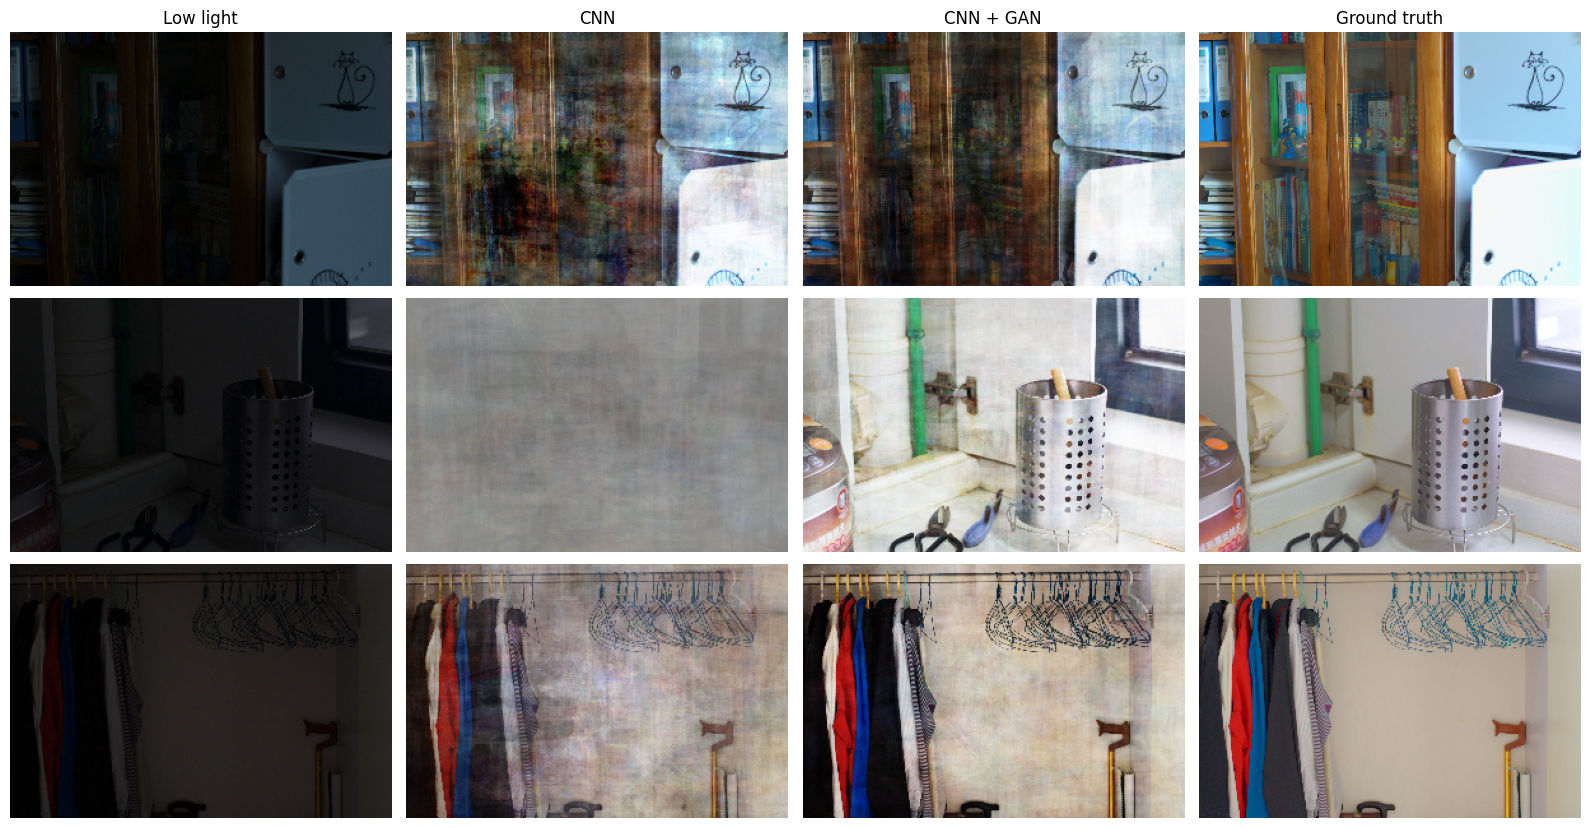

In [18]:
# Final comparison on the 15 held-out test images: input vs CNN vs CNN + GAN
cnn_model = load_model(CNN_BEST_PATH, compile=False)
gan_model = load_model(GAN_BEST_PATH, compile=False)
cnn_pred = cnn_model.predict(test_low_light_images, batch_size=8, verbose=0)
gan_pred = gan_model.predict(test_low_light_images, batch_size=8, verbose=0)

test_scores = {'input':   score(test_normal_light_images, test_low_light_images),
               'cnn':     score(test_normal_light_images, cnn_pred),
               'cnn_gan': score(test_normal_light_images, gan_pred)}
print('Input (no model):', test_scores['input'])
print('CNN             :', test_scores['cnn'])
print('CNN + GAN       :', test_scores['cnn_gan'])

# Saved so a final summary can compare all models side by side
with open(os.path.join(SAVE_DIR, f'{MODEL_NAME}_gan_test.json'), 'w') as f:
    json.dump(test_scores, f, indent=2)

show_results([test_low_light_images, cnn_pred, gan_pred, test_normal_light_images],
             ['Low light', 'CNN', 'CNN + GAN', 'Ground truth'])